In [42]:
import math
import random
import pandas as pd
from collections import Counter
from pathlib import Path
import kagglehub

# Seed agar hasil konsisten
random.seed(42)

import matplotlib.pyplot as plt
import seaborn as sns


In [43]:
# fungsi dan prosedur 

# fungsi normalisasi min-max tanpa library ML
def min_max_scale(data):
    mins = [min(col) for col in zip(*data)]
    maxs = [max(col) for col in zip(*data)]
    scaled = []
    for row in data:
        scaled.append([
            (row[i] - mins[i]) / (maxs[i] - mins[i]) if maxs[i] != mins[i] else 0.0
            for i in range(len(row))
        ])
    return scaled, mins, maxs

# fungsi denormalisasi (mengembalikan skala 0-1 ke satuan asli)
def denormalize_point(pt, mins, maxs):
    return [pt[i] * (maxs[i] - mins[i]) + mins[i] for i in range(len(pt))]

def init_centroid(c1,c2):
    return [c1,c2]

# jarak 
def euclidean(a,b):
    return math.sqrt(
        sum((a[i]-b[i])**2 for i in range(len(a)))
    )

# clustering
def clustering(x,centroid):
    klaster = []
    for i in x:
        jarak = [euclidean(i,c) for c in centroid]
        klaster.append(jarak.index(min(jarak)))
    return klaster

# update centroid
def update_centroid(x,clusters,k):
    new_centroid = []
    for i in range(k):
        anggota = [
            x[j] for j in range(len(x)) 
            if clusters[j] == i 
        ]
        if not anggota:
            continue
        centroid = [
            sum(col)/len(col)
            for col in zip(*anggota)
        ]
        new_centroid.append(centroid)
    return new_centroid

# akurasi
def hitung_akurasi(y_asli, y_pred):
    benar = sum(1 for a, b in zip(y_asli, y_pred) if a == b)
    return benar / len(y_asli)

# RMSE
def hitung_rmse(y_asli, y_pred):
    se = sum((a - b) ** 2 for a, b in zip(y_asli, y_pred))
    return math.sqrt(se / len(y_asli))

In [44]:
# inisialisasi data

import kagglehub
from pathlib import Path

# Download latest version (dengan fallback offline/cache)
try:
    path = kagglehub.dataset_download("dhairyajeetsingh/ecommerce-customer-behavior-dataset")
except Exception:
    cached_path = Path.home() / ".cache" / "kagglehub" / "datasets" / "dhairyajeetsingh" / "ecommerce-customer-behavior-dataset" / "versions" / "1"
    if cached_path.exists():
        path = str(cached_path)
    else:
        raise

print("Path to dataset files:", path)

# cari file csv di folder hasil download
data = next(Path(path).glob("*.csv"), None)
if data is None:
    raise FileNotFoundError("file csv tidak ditemukan di hasil download kaggle")

# membaca data (sampling 1000 baris agar komputasi cepat dan rapi)
df = pd.read_csv(data, nrows=1000)

kolom_fitur = [
    "Average_Order_Value",
    "Total_Purchases",
    "Pages_Per_Session",
    "Membership_Years"
]

# mengambil data 
df = df.dropna(subset=kolom_fitur).copy()

# menghapus data outlier: hanya mengambil nilai AOV di antara 60 dan 5000 (menghapus AOV < 60 dan AOV > 5000)
df = df[(df["Average_Order_Value"] >= 60) & (df["Average_Order_Value"] <= 5000)].copy()

# memastikan kolom ID tersedia untuk identifikasi data
if "ID" not in df.columns:
    df["ID"] = [f"P{i+1}" for i in range(len(df))]

# mengambil fitur mentah
x_raw = df[kolom_fitur].astype(float).values.tolist()

# menerapkan normalisasi Min-Max agar seluruh fitur berbobot setara
x, mins, maxs = min_max_scale(x_raw)
id_pelanggan = df["ID"].tolist()

# inisialisasi centroid
k = 2
max_iter = 10

# menggunakan data pelanggan pertama dan terakhir (skala ternormalisasi)
c1 = x[0].copy()
c2 = x[-1].copy()

centroid = init_centroid(c1, c2)

print("Jumlah data bersih (setelah filter outlier):", len(x))
print("Rentang AOV setelah dibersihkan: Min =", df["Average_Order_Value"].min(), "| Max =", df["Average_Order_Value"].max())
print("Fitur:", kolom_fitur)
print("Data ternormalisasi (3 sampel pertama):")
for baris in x[:3]:
    print(" ", [round(v, 4) for v in baris])
print("Centroid awal (Ternormalisasi):")
print("C1:", [round(v, 4) for v in c1])
print("C2:", [round(v, 4) for v in c2])

Path to dataset files: C:\Users\haida\.cache\kagglehub\datasets\dhairyajeetsingh\ecommerce-customer-behavior-dataset\versions\1
Jumlah data bersih (setelah filter outlier): 892
Rentang AOV setelah dibersihkan: Min = 60.24 | Max = 339.68
Fitur: ['Average_Order_Value', 'Total_Purchases', 'Pages_Per_Session', 'Membership_Years']
Data ternormalisasi (3 sampel pertama):
  [0.1234, 0.0851, 0.2294, 0.2828]
  [0.0795, 0.1968, 0.4266, 0.1515]
  [0.3768, 0.0862, 0.0275, 0.2828]
Centroid awal (Ternormalisasi):
C1: [0.1234, 0.0851, 0.2294, 0.2828]
C2: [0.3567, 0.0862, 0.2661, 0.4545]


In [45]:
# main program

for iterasi in range(max_iter):
    # menyimpan centroid lama
    centroid_lama = [c.copy() for c in centroid]
    # menentukan klaster
    klaster = clustering(x,centroid)
    # menghitung centroid baru
    centroid = update_centroid(x,klaster,k)
    print(f"Iterasi ke-{iterasi+1}")
    for i, c in enumerate(centroid):
        print(f"Centroid {i+1}: {c}")
    # berhenti jika centroid tidak berubah
    if  centroid == centroid_lama:
        print("Centroid konvergen.")
        break


Iterasi ke-1
Centroid 1: [0.16005215334346456, 0.12414017960278668, 0.3322514821896238, 0.20249720762994394]
Centroid 2: [0.3445212632652932, 0.13658447670179594, 0.38544971276686935, 0.4526888825954245]
Iterasi ke-2
Centroid 1: [0.18091368476169495, 0.12378671419553626, 0.3285860672142433, 0.1835451310683291]
Centroid 2: [0.3082055288364458, 0.13729740545587915, 0.3923672025538521, 0.48829992717140014]
Iterasi ke-3
Centroid 1: [0.2007331427705682, 0.12282847115595485, 0.3277057914814464, 0.17563894356126752]
Centroid 2: [0.2746916644348604, 0.13948867536032922, 0.3958715596330272, 0.5119908765070051]
Iterasi ke-4
Centroid 1: [0.21388000252997688, 0.12348024316109393, 0.3306943216800268, 0.17703554901360977]
Centroid 2: [0.2525011846352803, 0.1392846661775493, 0.39436887061056614, 0.532288401253918]
Iterasi ke-5
Centroid 1: [0.2220160913434297, 0.12408729210067944, 0.3333603310409825, 0.18134741719138595]
Centroid 2: [0.2366731604472887, 0.1391125524005376, 0.3931653081409229, 0.550035

In [46]:
# Menentukan klaster berdasarkan centroid akhir
klaster = clustering(x, centroid)

df["Klaster"] = [
    f"C{nomor + 1}" for nomor in klaster
]
df["Label"] = klaster

# Menyimpan seluruh data hasil klaster
nama_file = "dt_klaster_pelanggan.xlsx"
df.to_excel(nama_file, index=False)

print(f"\nHasil klaster berhasil disimpan ke file: {nama_file}")

print("\nCentroid akhir (Skala Ternormalisasi 0-1):")
for i, c in enumerate(centroid):
    print(f"C{i + 1}: {[round(v, 4) for v in c]}")

print("\nCentroid akhir (Skala Asli / Denormalized):")
for i, c in enumerate(centroid):
    c_asli = denormalize_point(c, mins, maxs)
    print(f"C{i + 1}: {[round(v, 2) for v in c_asli]}")

print("\nHasil pengelompokan pelanggan (20 data pertama):")
print(df[["ID"] + kolom_fitur + ["Klaster"]].head(20).to_string(index=False))

print("\nJumlah anggota setiap klaster:")
print(df["Klaster"].value_counts().sort_index())


Hasil klaster berhasil disimpan ke file: dt_klaster_pelanggan.xlsx

Centroid akhir (Skala Ternormalisasi 0-1):
C1: [0.2257, 0.1248, 0.3356, 0.1837]
C2: [0.2281, 0.138, 0.3901, 0.5586]

Centroid akhir (Skala Asli / Denormalized):
C1: [123.32, 12.73, 8.32, 1.92]
C2: [123.99, 13.98, 9.5, 5.63]

Hasil pengelompokan pelanggan (20 data pertama):
 ID  Average_Order_Value  Total_Purchases  Pages_Per_Session  Membership_Years Klaster
 P1                94.72              9.0                6.0               2.9      C1
 P2                82.45             19.5               10.3               1.6      C1
 P3               165.52              9.1                1.6               2.9      C1
 P4               147.33             15.0               14.8               2.6      C1
 P5               190.97             12.0                6.9               3.5      C1
 P6               169.58             20.0               13.9               1.9      C1
 P7               161.98             13.0       

### Visualisasi Hasil Pengelompokan K-Means (Seluruh Data)
Berikut adalah visualisasi hasil pengelompokan pelanggan menggunakan K-Means:
1. **Scatter Plot Fitur Utama (AOV vs Total Purchases)** beserta titik Centroid (C1 & C2).
2. **Scatter Plot Fitur Perilaku (Pages per Session vs Membership Years)**.
3. **Diagram Batang Distribusi Anggota** pada masing-masing klaster.

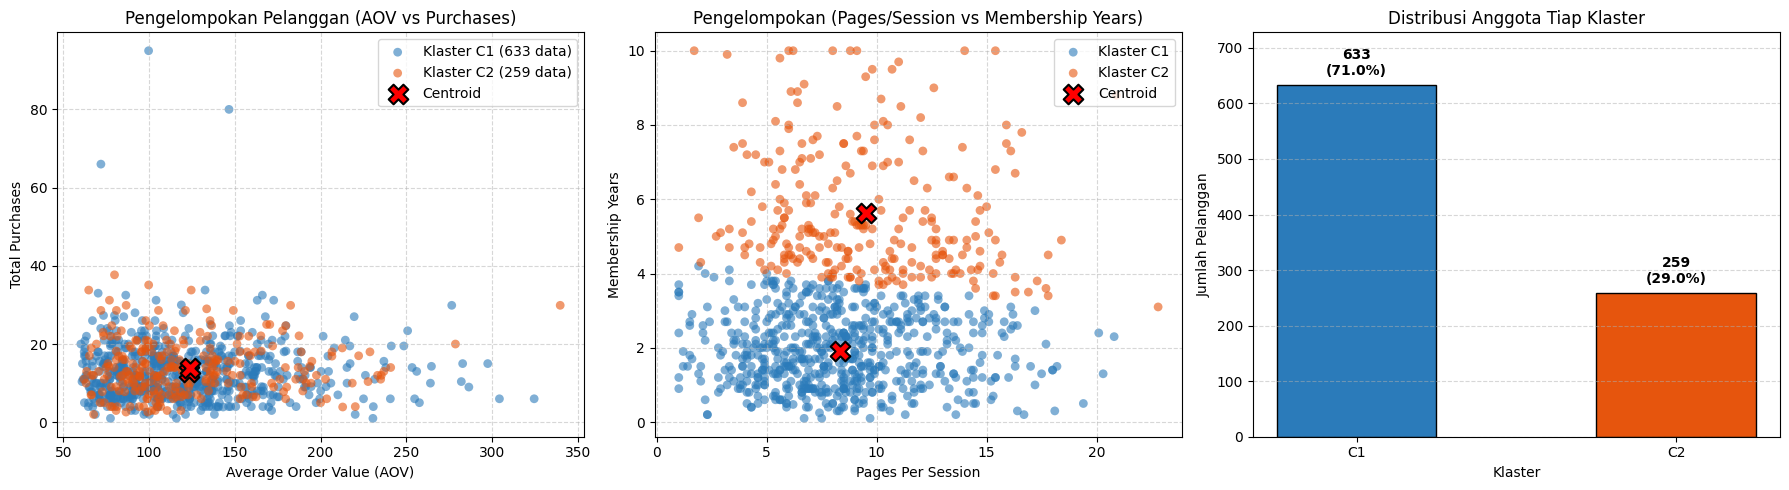

In [47]:
# Visualisasi hasil pengelompokan K-Means untuk seluruh data
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
warna_klaster = {'C1': '#2b7bba', 'C2': '#e6550d'}

# Mengembalikan posisi centroid ke skala asli agar selaras dengan data df
c1_asli = denormalize_point(centroid[0], mins, maxs)
c2_asli = denormalize_point(centroid[1], mins, maxs)

# 1. Scatter Plot: Average Order Value vs Total Purchases
for k_label, color in warna_klaster.items():
    sub = df[df['Klaster'] == k_label]
    axes[0].scatter(sub['Average_Order_Value'], sub['Total_Purchases'], 
                    c=color, label=f'Klaster {k_label} ({len(sub)} data)', alpha=0.6, edgecolors='none', s=40)
axes[0].scatter([c1_asli[0], c2_asli[0]], [c1_asli[1], c2_asli[1]], 
                c='red', s=200, marker='X', edgecolors='black', linewidth=1.5, label='Centroid', zorder=5)
axes[0].set_xlabel('Average Order Value (AOV)')
axes[0].set_ylabel('Total Purchases')
axes[0].set_title('Pengelompokan Pelanggan (AOV vs Purchases)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Scatter Plot: Pages Per Session vs Membership Years
for k_label, color in warna_klaster.items():
    sub = df[df['Klaster'] == k_label]
    axes[1].scatter(sub['Pages_Per_Session'], sub['Membership_Years'], 
                    c=color, label=f'Klaster {k_label}', alpha=0.6, edgecolors='none', s=40)
axes[1].scatter([c1_asli[2], c2_asli[2]], [c1_asli[3], c2_asli[3]], 
                c='red', s=200, marker='X', edgecolors='black', linewidth=1.5, label='Centroid', zorder=5)
axes[1].set_xlabel('Pages Per Session')
axes[1].set_ylabel('Membership Years')
axes[1].set_title('Pengelompokan (Pages/Session vs Membership Years)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Bar Chart: Distribusi Jumlah Anggota Tiap Klaster
counts = df['Klaster'].value_counts().sort_index()
bars = axes[2].bar(counts.index, counts.values, color=['#2b7bba', '#e6550d'], edgecolor='black', width=0.5)
axes[2].set_xlabel('Klaster')
axes[2].set_ylabel('Jumlah Pelanggan')
axes[2].set_title('Distribusi Anggota Tiap Klaster')
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
axes[2].set_ylim(0, max(counts.values) * 1.15)
for bar in bars:
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2.0, yval + (max(counts.values)*0.02), 
                 f"{yval}\n({yval/len(df)*100:.1f}%)", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

In [48]:
# soal 1: langkah pengujian: split data latih/uji 80/20, hitung akurasi dan RMSE

# program K-NN tanpa library ML
def knn_predict_point(x_train, y_train, test_point, k_neighbors=3):
    jarak_list = [(euclidean(test_point, xt), yt) for xt, yt in zip(x_train, y_train)]
    jarak_list.sort(key=lambda item: item[0])
    tetangga_terdekat = [label for _, label in jarak_list[:k_neighbors]]
    return Counter(tetangga_terdekat).most_common(1)[0][0]

def knn_predict_all(x_train, y_train, x_test, k_neighbors=3):
    return [knn_predict_point(x_train, y_train, pt, k_neighbors) for pt in x_test]

# split data 80% data latih dan 20% data uji (menggunakan data ternormalisasi)
idx = list(range(len(x)))
random.shuffle(idx)
batas = int(0.8 * len(x))
train_idx, test_idx = idx[:batas], idx[batas:]

x_latih = [x[i] for i in train_idx]
x_latih_raw = [x_raw[i] for i in train_idx]
y_latih = [df["Label"].iloc[i] for i in train_idx]

x_uji = [x[i] for i in test_idx]
y_uji = [df["Label"].iloc[i] for i in test_idx]

# jalankan prediksi K-NN (k=3)
y_pred_knn = knn_predict_all(x_latih, y_latih, x_uji, k_neighbors=3)

acc_knn = hitung_akurasi(y_uji, y_pred_knn)
err_knn = hitung_rmse(y_uji, y_pred_knn)

print("Data latih:", len(x_latih), "(80%) | Data uji:", len(x_uji), "(20%)")
print("Akurasi data uji K-NN: %.4f (%.2f%%)" % (acc_knn, acc_knn * 100))
print("RMSE data uji K-NN   : %.4f" % err_knn)

Data latih: 713 (80%) | Data uji: 179 (20%)
Akurasi data uji K-NN: 0.9721 (97.21%)
RMSE data uji K-NN   : 0.1671


In [49]:
# soal 3: eksperimen perhitungan manual dengan 20 data pertama
x20 = x[:20]
id20 = id_pelanggan[:20]

# menggunakan data pertama dan terakhir dari 20 data sebagai centroid awal
c1_20 = x20[0].copy()
c2_20 = x20[-1].copy()
centroid20 = init_centroid(c1_20, c2_20)

print("== K-Means pada 20 Data Pertama ==")
for it in range(10):
    c_lama20 = [c.copy() for c in centroid20]
    klas20 = clustering(x20, centroid20)
    centroid20 = update_centroid(x20, klas20, 2)
    print(f"Iterasi ke-{it + 1}:")
    for i, c in enumerate(centroid20):
        print(f"  Centroid {i + 1}: {[round(v, 4) for v in c]}")
    if centroid20 == c_lama20:
        print("Centroid konvergen.\n")
        break

df20 = df.iloc[:20].copy()
df20["Klaster"] = [f"C{n + 1}" for n in klas20]
print("Hasil klaster 20 data:")
print(df20[["ID"] + kolom_fitur + ["Klaster"]].to_string(index=False))
print("\nJumlah anggota klaster 20 data:")
print(df20["Klaster"].value_counts().sort_index())


== K-Means pada 20 Data Pertama ==
Iterasi ke-1:
  Centroid 1: [0.1924, 0.1017, 0.2643, 0.2551]
  Centroid 2: [0.2473, 0.1941, 0.6732, 0.1692]
Iterasi ke-2:
  Centroid 1: [0.1924, 0.1017, 0.2643, 0.2551]
  Centroid 2: [0.2473, 0.1941, 0.6732, 0.1692]
Centroid konvergen.

Hasil klaster 20 data:
 ID  Average_Order_Value  Total_Purchases  Pages_Per_Session  Membership_Years Klaster
 P1                94.72              9.0                6.0               2.9      C1
 P2                82.45             19.5               10.3               1.6      C1
 P3               165.52              9.1                1.6               2.9      C1
 P4               147.33             15.0               14.8               2.6      C2
 P5               190.97             12.0                6.9               3.5      C1
 P6               169.58             20.0               13.9               1.9      C2
 P7               161.98             13.0                8.3               1.6      C1
 P8      

### Visualisasi Pengelompokan K-Means pada 20 Data Pertama (Soal 3)
Plot di bawah menunjukkan pemetaan 20 data pelanggan pertama lengkap dengan ID Pelanggan (`P1` - `P20`) dan posisi Centroid akhir.

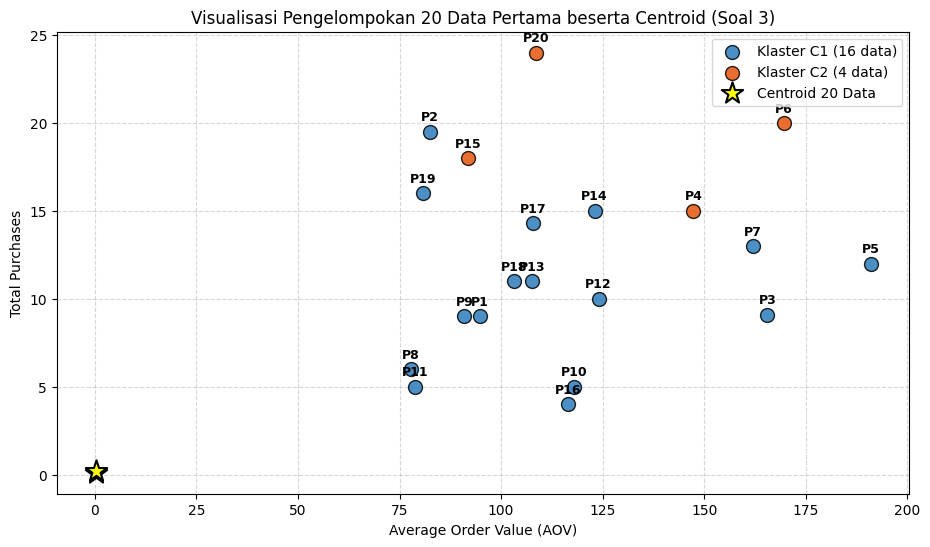

In [50]:
# Visualisasi hasil pengelompokan pada 20 data pertama
plt.figure(figsize=(11, 6))

for k_label, color in warna_klaster.items():
    sub20 = df20[df20['Klaster'] == k_label]
    plt.scatter(sub20['Average_Order_Value'], sub20['Total_Purchases'],
                c=color, label=f'Klaster {k_label} ({len(sub20)} data)', s=100, edgecolors='black', alpha=0.85, zorder=3)

# Menambahkan label ID pelanggan pada setiap titik
for _, row in df20.iterrows():
    plt.annotate(row['ID'], (row['Average_Order_Value'], row['Total_Purchases']),
                 textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9, fontweight='bold')

# Menampilkan centroid akhir dari 20 data
plt.scatter([centroid20[0][0], centroid20[1][0]], 
            [centroid20[0][1], centroid20[1][1]], 
            c='yellow', s=260, marker='*', edgecolors='black', linewidth=1.5, label='Centroid 20 Data', zorder=5)

plt.xlabel('Average Order Value (AOV)')
plt.ylabel('Total Purchases')
plt.title('Visualisasi Pengelompokan 20 Data Pertama beserta Centroid (Soal 3)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [51]:
# soal 4 & 5: perbandingan data baru: dihitung jarak ke centroid vs metode K-NN

def centroid_predict_point(centroids, test_point):
    jarak = [euclidean(test_point, c) for c in centroids]
    return jarak.index(min(jarak))

def centroid_predict_all(centroids, x_test):
    return [centroid_predict_point(centroids, pt) for pt in x_test]

# 1. Perbandingan pada data baru spesifik (Soal 4)
data_baru_raw = [220.0, 15.0, 10.0, 3.0]

# Normalisasi data baru menggunakan nilai min dan max dari data latih
data_baru = [
    (data_baru_raw[i] - mins[i]) / (maxs[i] - mins[i]) if maxs[i] != mins[i] else 0.0
    for i in range(len(data_baru_raw))
]

jarak_list = [(euclidean(data_baru, xt), yt) for xt, yt in zip(x_latih, y_latih)]
jarak_list.sort(key=lambda item: item[0])
top3_knn = jarak_list[:3]
vote_knn = Counter([yt for _, yt in top3_knn]).most_common(1)[0][0]

d_c1 = euclidean(data_baru, centroid[0])
d_c2 = euclidean(data_baru, centroid[1])
pred_cen_baru = 0 if d_c1 < d_c2 else 1

print("== 1. Pengujian pada Data Baru Spesifik ==")
print(f"Data Baru (Skala Asli)         : {data_baru_raw}")
print(f"Data Baru (Skala Ternormalisasi): {[round(v, 4) for v in data_baru]}")
print("3 Tetangga terdekat di data latih:")
for d, l in top3_knn:
    print(f"  - Jarak: {d:.4f} -> Klaster C{l + 1}")
print(f"Hasil prediksi K-NN       : C{vote_knn + 1}")
print(f"Jarak ke Centroid 1: {d_c1:.4f} | Jarak ke Centroid 2: {d_c2:.4f}")
print(f"Hasil prediksi Jarak Centroid: C{pred_cen_baru + 1}\n")

# 2. Evaluasi pada data uji (Soal 5)
y_pred_cen = centroid_predict_all(centroid, x_uji)

acc_cen = hitung_akurasi(y_uji, y_pred_cen)
err_cen = hitung_rmse(y_uji, y_pred_cen)

print(f"== 2. Evaluasi pada {len(x_uji)} Data Uji ==")
print("Metode K-NN (k=3)     : Akurasi=%.4f (%.2f%%)  RMSE=%.4f" % (acc_knn, acc_knn * 100, err_knn))
print("Metode Jarak Centroid : Akurasi=%.4f (%.2f%%)  RMSE=%.4f" % (acc_cen, acc_cen * 100, err_cen))
print()

# Cek data yang berbeda/salah prediksi
salah_knn = [i + 1 for i in range(len(y_uji)) if y_uji[i] != y_pred_knn[i]]
salah_cen = [i + 1 for i in range(len(y_uji)) if y_uji[i] != y_pred_cen[i]]
print("Data salah K-NN     :", salah_knn)
print("Data salah Centroid :", salah_cen)

== 1. Pengujian pada Data Baru Spesifik ==
Data Baru (Skala Asli)         : [220.0, 15.0, 10.0, 3.0]
Data Baru (Skala Ternormalisasi): [0.5717, 0.1489, 0.4128, 0.2929]
3 Tetangga terdekat di data latih:
  - Jarak: 0.0910 -> Klaster C2
  - Jarak: 0.1045 -> Klaster C1
  - Jarak: 0.1177 -> Klaster C1
Hasil prediksi K-NN       : C1
Jarak ke Centroid 1: 0.3717 | Jarak ke Centroid 2: 0.4350
Hasil prediksi Jarak Centroid: C1

== 2. Evaluasi pada 179 Data Uji ==
Metode K-NN (k=3)     : Akurasi=0.9721 (97.21%)  RMSE=0.1671
Metode Jarak Centroid : Akurasi=1.0000 (100.00%)  RMSE=0.0000

Data salah K-NN     : [24, 115, 137, 152, 164]
Data salah Centroid : []


### Visualisasi Pengujian Data Baru & K-NN vs Jarak Centroid (Soal 4 & 5)
Plot di bawah memperlihatkan posisi **Data Baru**, garis jarak ke **3 Tetangga Terdekat (K-NN)**, dan perbandingannya terhadap posisi **Centroid**.

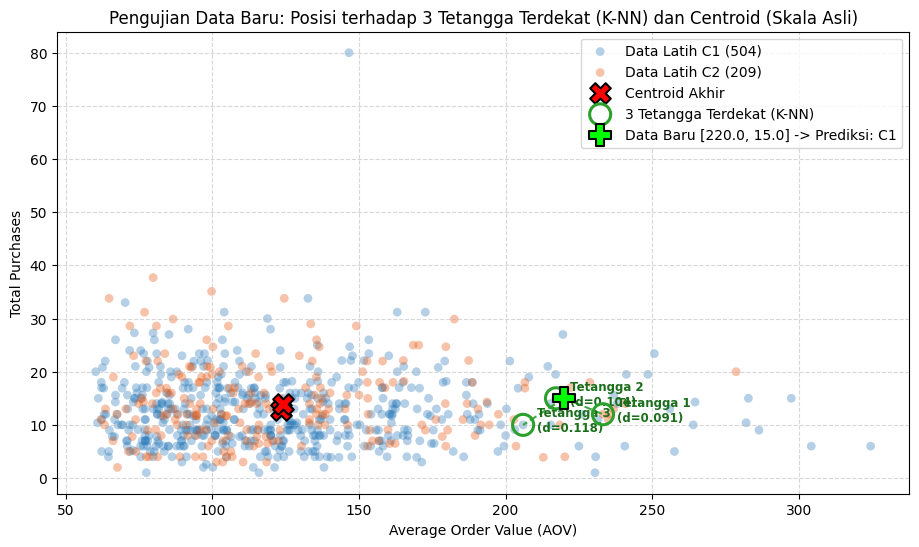

In [52]:
# Visualisasi Data Baru & 3 Tetangga Terdekat K-NN
plt.figure(figsize=(11, 6))

c1_asli = denormalize_point(centroid[0], mins, maxs)
c2_asli = denormalize_point(centroid[1], mins, maxs)

x_latih_c1 = [pt_raw for pt_raw, yt in zip(x_latih_raw, y_latih) if yt == 0]
x_latih_c2 = [pt_raw for pt_raw, yt in zip(x_latih_raw, y_latih) if yt == 1]

# Plot sebaran data latih pada skala asli
plt.scatter([p[0] for p in x_latih_c1], [p[1] for p in x_latih_c1], 
            c='#2b7bba', label=f'Data Latih C1 ({len(x_latih_c1)})', alpha=0.35, edgecolors='none', s=40)
plt.scatter([p[0] for p in x_latih_c2], [p[1] for p in x_latih_c2], 
            c='#e6550d', label=f'Data Latih C2 ({len(x_latih_c2)})', alpha=0.35, edgecolors='none', s=40)

# Plot Centroid asli
plt.scatter([c1_asli[0], c2_asli[0]], [c1_asli[1], c2_asli[1]], 
            c='red', s=220, marker='X', edgecolors='black', linewidth=1.5, label='Centroid Akhir', zorder=4)

# Ambil 3 tetangga terdekat beserta koordinat aslinya
jarak_dengan_titik = [(euclidean(data_baru, xt), yt, pt_raw) for xt, yt, pt_raw in zip(x_latih, y_latih, x_latih_raw)]
jarak_dengan_titik.sort(key=lambda item: item[0])
top3_knn_pts = jarak_dengan_titik[:3]

# Hubungkan Data Baru dengan 3 tetangga terdekat K-NN
for rank, (dist, yt, pt_raw) in enumerate(top3_knn_pts):
    label_tetangga = '3 Tetangga Terdekat (K-NN)' if rank == 0 else ""
    plt.scatter(pt_raw[0], pt_raw[1], facecolors='none', edgecolors='#2ca02c', s=230, linewidth=2.2, zorder=5, label=label_tetangga)
    plt.plot([data_baru_raw[0], pt_raw[0]], [data_baru_raw[1], pt_raw[1]], color='#2ca02c', linestyle='--', linewidth=1.5, alpha=0.9)
    plt.annotate(f"Tetangga {rank+1}\n(d={dist:.3f})", (pt_raw[0], pt_raw[1]),
                 textcoords="offset points", xytext=(10, -5), fontsize=8.5, color='#1b6e1b', fontweight='bold')

# Plot titik Data Baru
plt.scatter(data_baru_raw[0], data_baru_raw[1], c='#00ff00', s=250, marker='P', edgecolors='black', linewidth=1.5,
            label=f'Data Baru {data_baru_raw[:2]} -> Prediksi: C{vote_knn + 1}', zorder=6)

plt.xlabel('Average Order Value (AOV)')
plt.ylabel('Total Purchases')
plt.title('Pengujian Data Baru: Posisi terhadap 3 Tetangga Terdekat (K-NN) dan Centroid (Skala Asli)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()